In [90]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Load Dataset

In [91]:
df = pd.read_csv('../data/thyroid_recurrence.csv')
df.head(5)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


## 2. Explore the data (EDA)

In [92]:
df.describe()

,Age
count,383.000000
mean,40.866841
std,15.134494
min,15.000000
25%,29.000000
50%,37.000000
75%,51.000000
max,82.000000


In [93]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [94]:
df = df.rename(columns={
    'T':'tumors',
    'N':'nodes',
    'M':'metastasis'})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  tumors                383 non-null    str  
 12  nodes                 383 non-null    str  
 13  metastasis            383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

In [95]:
# Make column names to be consistent and easier to work with
df.columns = df.columns.str.strip().str.lower().str.replace(' ','_')
df.columns

Index(['age', 'gender', 'smoking', 'hx_smoking', 'hx_radiothreapy',
       'thyroid_function', 'physical_examination', 'adenopathy', 'pathology',
       'focality', 'risk', 'tumors', 'nodes', 'metastasis', 'stage',
       'response', 'recurred'],
      dtype='str')

In [96]:
# Identify object columns
object_cols = list(df.dtypes[df.dtypes == 'str'].index)
object_cols

['gender',
 'smoking',
 'hx_smoking',
 'hx_radiothreapy',
 'thyroid_function',
 'physical_examination',
 'adenopathy',
 'pathology',
 'focality',
 'risk',
 'tumors',
 'nodes',
 'metastasis',
 'stage',
 'response',
 'recurred']

In [97]:
# Strip whitespace from object columns and check value counts in each features
for col in object_cols:
    df[col] = df[col].str.strip()
    print(df[col].value_counts())

gender
F    312
M     71
Name: count, dtype: int64
smoking
No     334
Yes     49
Name: count, dtype: int64
hx_smoking
No     355
Yes     28
Name: count, dtype: int64
hx_radiothreapy
No     376
Yes      7
Name: count, dtype: int64
thyroid_function
Euthyroid                      332
Clinical Hyperthyroidism        20
Subclinical Hypothyroidism      14
Clinical Hypothyroidism         12
Subclinical Hyperthyroidism      5
Name: count, dtype: int64
physical_examination
Multinodular goiter            140
Single nodular goiter-right    140
Single nodular goiter-left      89
Normal                           7
Diffuse goiter                   7
Name: count, dtype: int64
adenopathy
No           277
Right         48
Bilateral     32
Left          17
Extensive      7
Posterior      2
Name: count, dtype: int64
pathology
Papillary         287
Micropapillary     48
Follicular         28
Hurthel cell       20
Name: count, dtype: int64
focality
Uni-Focal      247
Multi-Focal    136
Name: count, dtype: 

In [98]:
object_cols

['gender',
 'smoking',
 'hx_smoking',
 'hx_radiothreapy',
 'thyroid_function',
 'physical_examination',
 'adenopathy',
 'pathology',
 'focality',
 'risk',
 'tumors',
 'nodes',
 'metastasis',
 'stage',
 'response',
 'recurred']

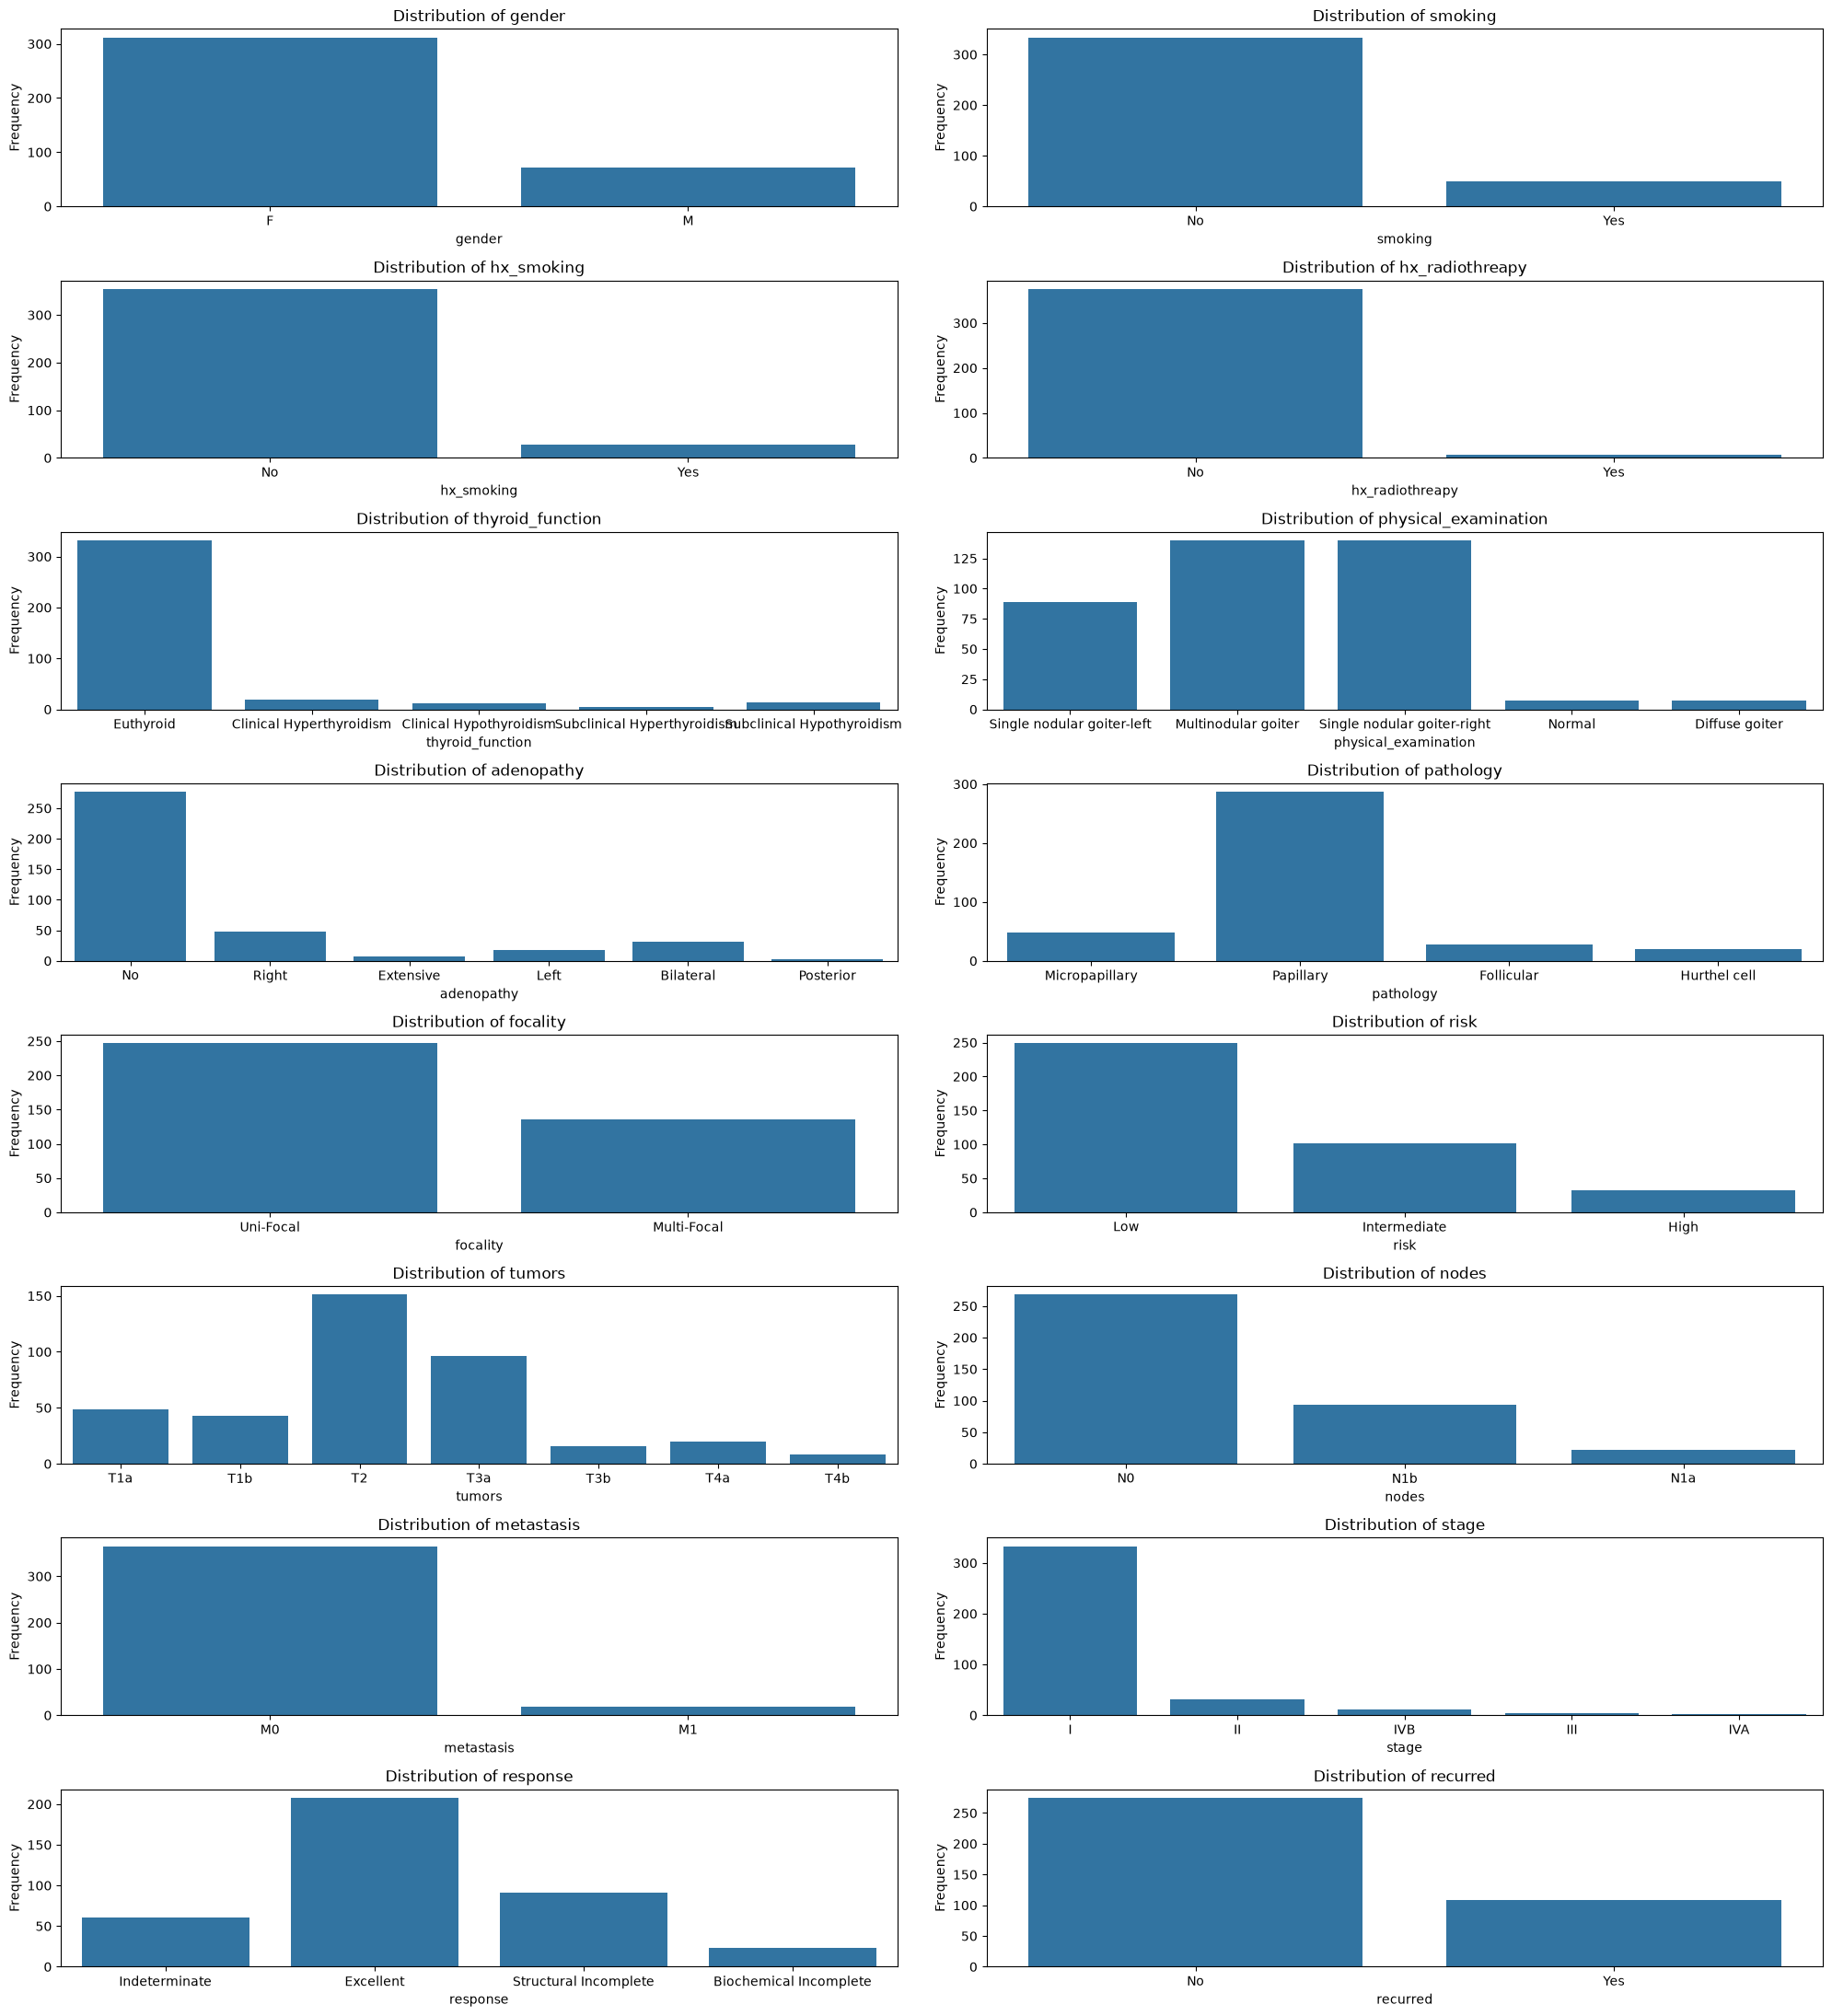

In [99]:
fig,axes = plt.subplots(figsize=(20,22),nrows=8,ncols=2)
axes = axes.flatten()
for index,col in enumerate(object_cols):
    sns.countplot(data=df,x=col,ax=axes[index])
    axes[index].set_title(f'Distribution of {col}')
    axes[index].set_xlabel(col)
    axes[index].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

In [117]:
df['gender'].value_counts()

gender
F    312
M     71
Name: count, dtype: int64

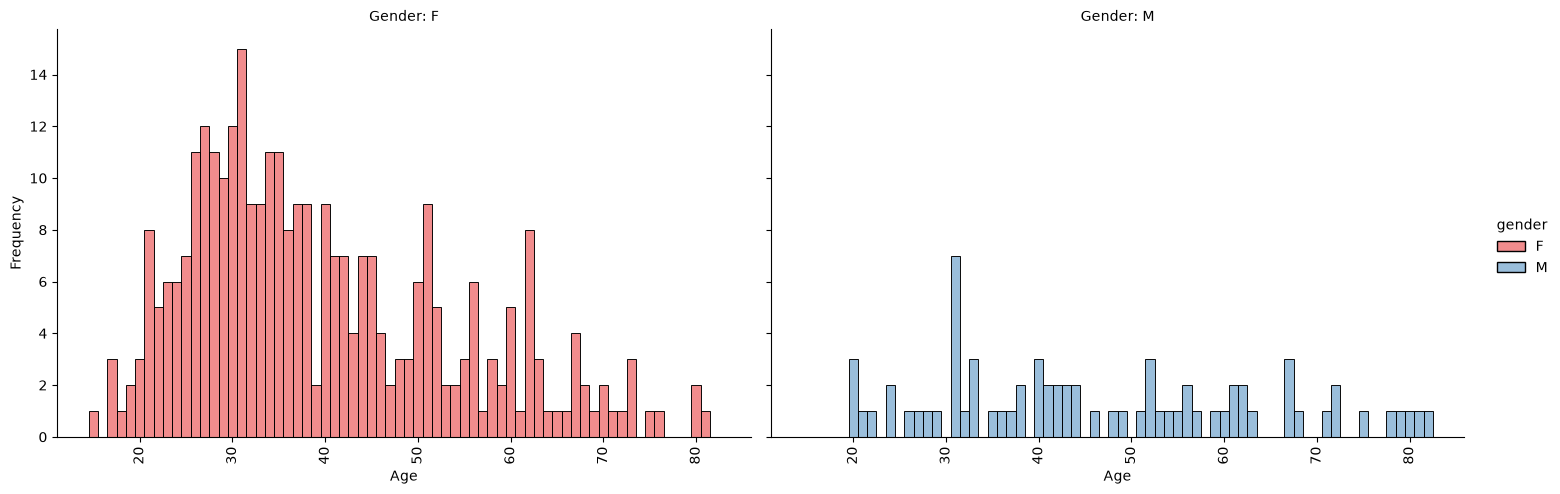

In [116]:
# Distribution of age by gender
g = sns.displot(
    data=df,
    x='age',
    col='gender',
    hue='gender',
    kind='hist',
    discrete=True,
    palette='Set1',
    height=5,
    aspect=1.5
)

g.set_axis_labels('Age', 'Frequency')
g.set_titles('Gender: {col_name}')
g.tick_params(axis='x', rotation=90)

plt.show()

The majority of people in the population are between the age of 20-30 in female. For male, out of 71 people, the highest number of people age range is between 30-40. 



Moreover, since we have gender imbalance comparing raw recurrence counts is misleading. Instead of that calculate the percentage of reccurence for each gender.

In [121]:
# Recurrence percentage within each gender
recurrence_pct = pd.crosstab(
    df['gender'],
    df['recurred'],
    normalize='index'
) * 100

print(recurrence_pct)


recurred         No        Yes
gender                        
F         78.846154  21.153846
M         40.845070  59.154930


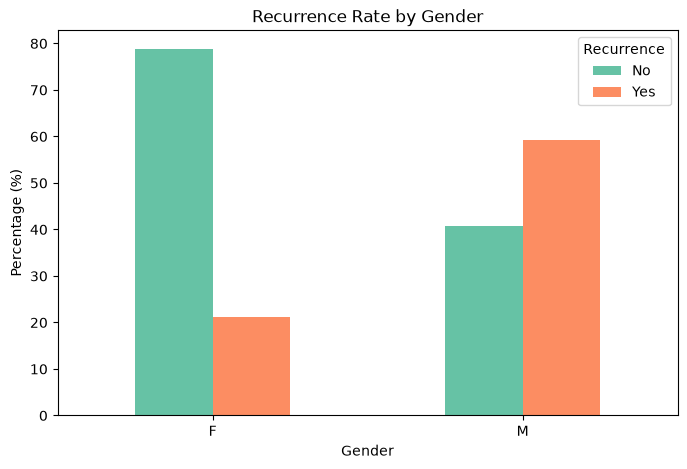

In [125]:
recurrence_pct.plot(
    kind='bar',
    figsize=(8, 5),
    color=['#66c2a5', '#fc8d62']
)

plt.title('Recurrence Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Recurrence')
plt.show()

Interestingly, even though female patients are more numerous, male patients appear to have a substantially higher recurrence proportion in this sample.

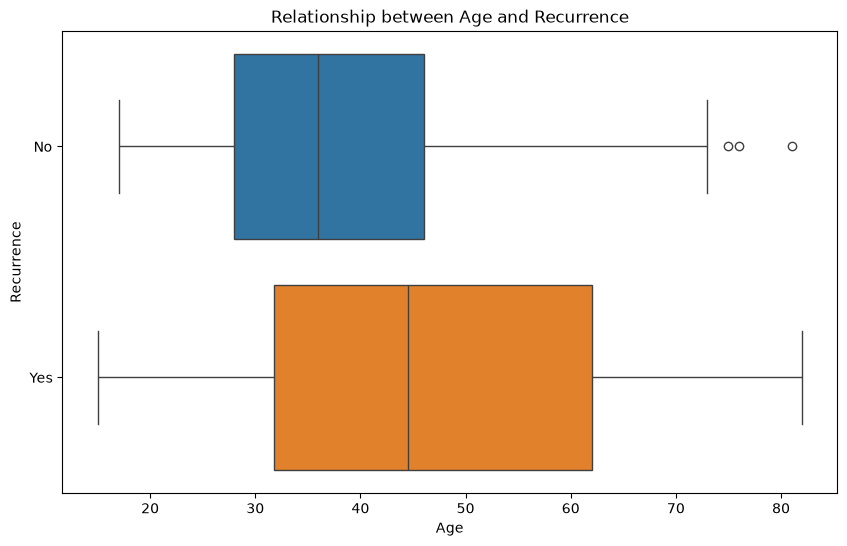

In [123]:
# Relationship between Age and Recurrence
fig,ax = plt.subplots(figsize=(10,6))
sns.boxplot(data=df,x='age',y='recurred',hue='recurred')
plt.title('Relationship between Age and Recurrence')
plt.xlabel('Age')
plt.ylabel('Recurrence')
plt.show()

This suggests a possible association between older age and thyroid cancer recurrence, although further statistical analysis is needed to determine its significance.

In [129]:
df['smoking'].value_counts()

smoking
No     334
Yes     49
Name: count, dtype: int64

In [130]:
df['hx_smoking'].value_counts()

hx_smoking
No     355
Yes     28
Name: count, dtype: int64

Just like gender, compare recurrence rates within each smoking category rather than raw counts.

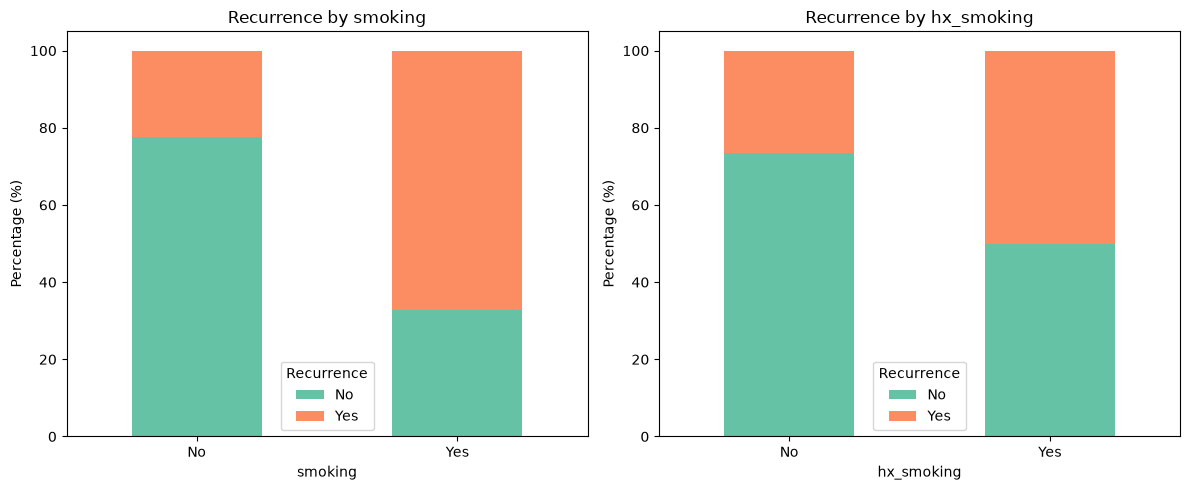

In [131]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ['smoking', 'hx_smoking']):
    pct = pd.crosstab(
        df[col],
        df['recurred'],
        normalize='index'
    ) * 100

    pct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['#66c2a5', '#fc8d62']
    )

    ax.set_title(f'Recurrence by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage (%)')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Recurrence')

plt.tight_layout()
plt.show()

Smoking status: Approximately 67% of smokers experienced recurrence, compared with 22% of nonsmokers. This suggests a substantial association between smoking status and recurrence in your sample.


History of smoking: Approximately 50% of patients with a smoking history experienced recurrence, compared with 26% of patients without a smoking history.

However, these results are descriptive. They do not establish that smoking causes recurrence, and other variables such as age, gender, tumour stage, and risk classification could be confounds for this relationship.

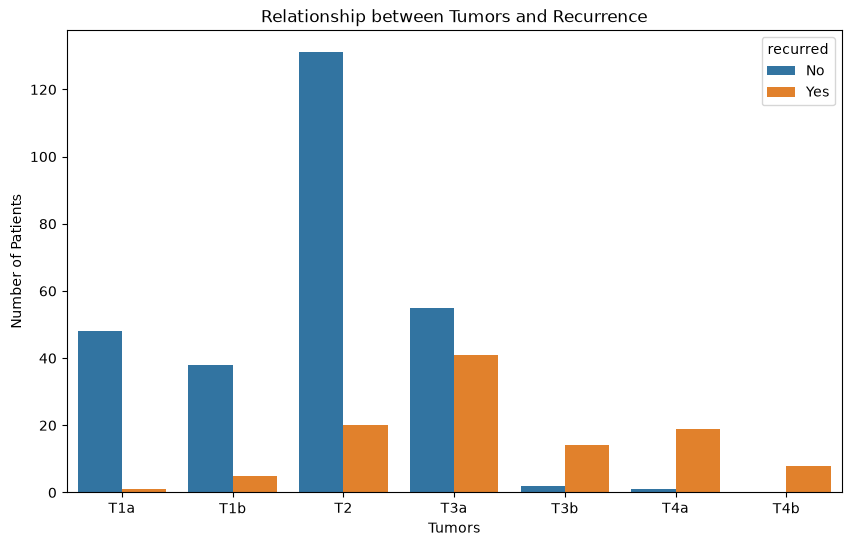

In [ ]:
# Relationship between tumors and recurrence
fig, ax = plt.subplots(figsize=(10, 6))

sns.countplot(
    data=df,
    x='tumors',
    hue='recurred',
    ax=ax
)
ax.set_title('Relationship between Tumors and Recurrence')
ax.set_xlabel('Tumors')
ax.set_ylabel('Number of Patients')

plt.show()

T3b, T4a and T4b has highest recurrence rate. It suggests that tumors less than T3 has lower recurrence rate.

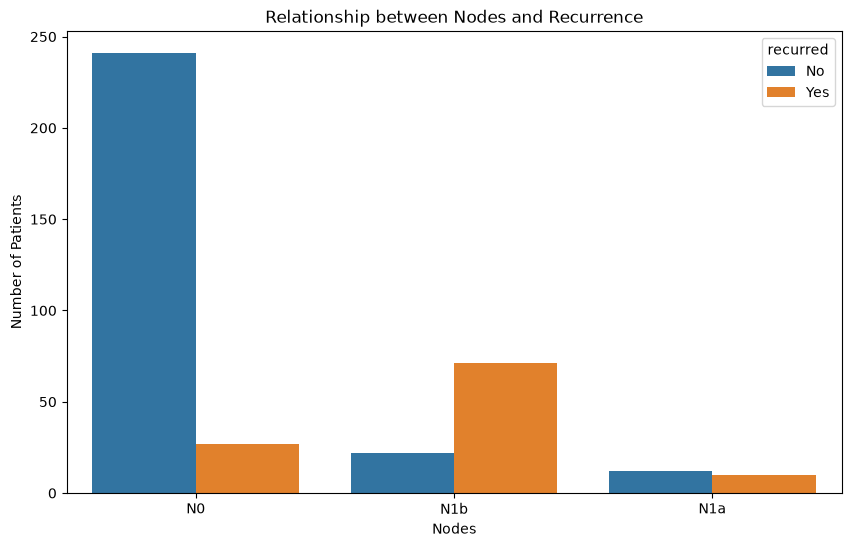

In [ ]:
# Relationship between nodes and recurrence
fig, ax = plt.subplots(figsize=(10, 6))

sns.countplot(
    data=df,
    x='nodes',
    hue='recurred',
    ax=ax
)
ax.set_title('Relationship between Nodes and Recurrence')
ax.set_xlabel('Nodes')
ax.set_ylabel('Number of Patients')

plt.show()

N1b nodes has higher reccurence risk among different types of nodes.

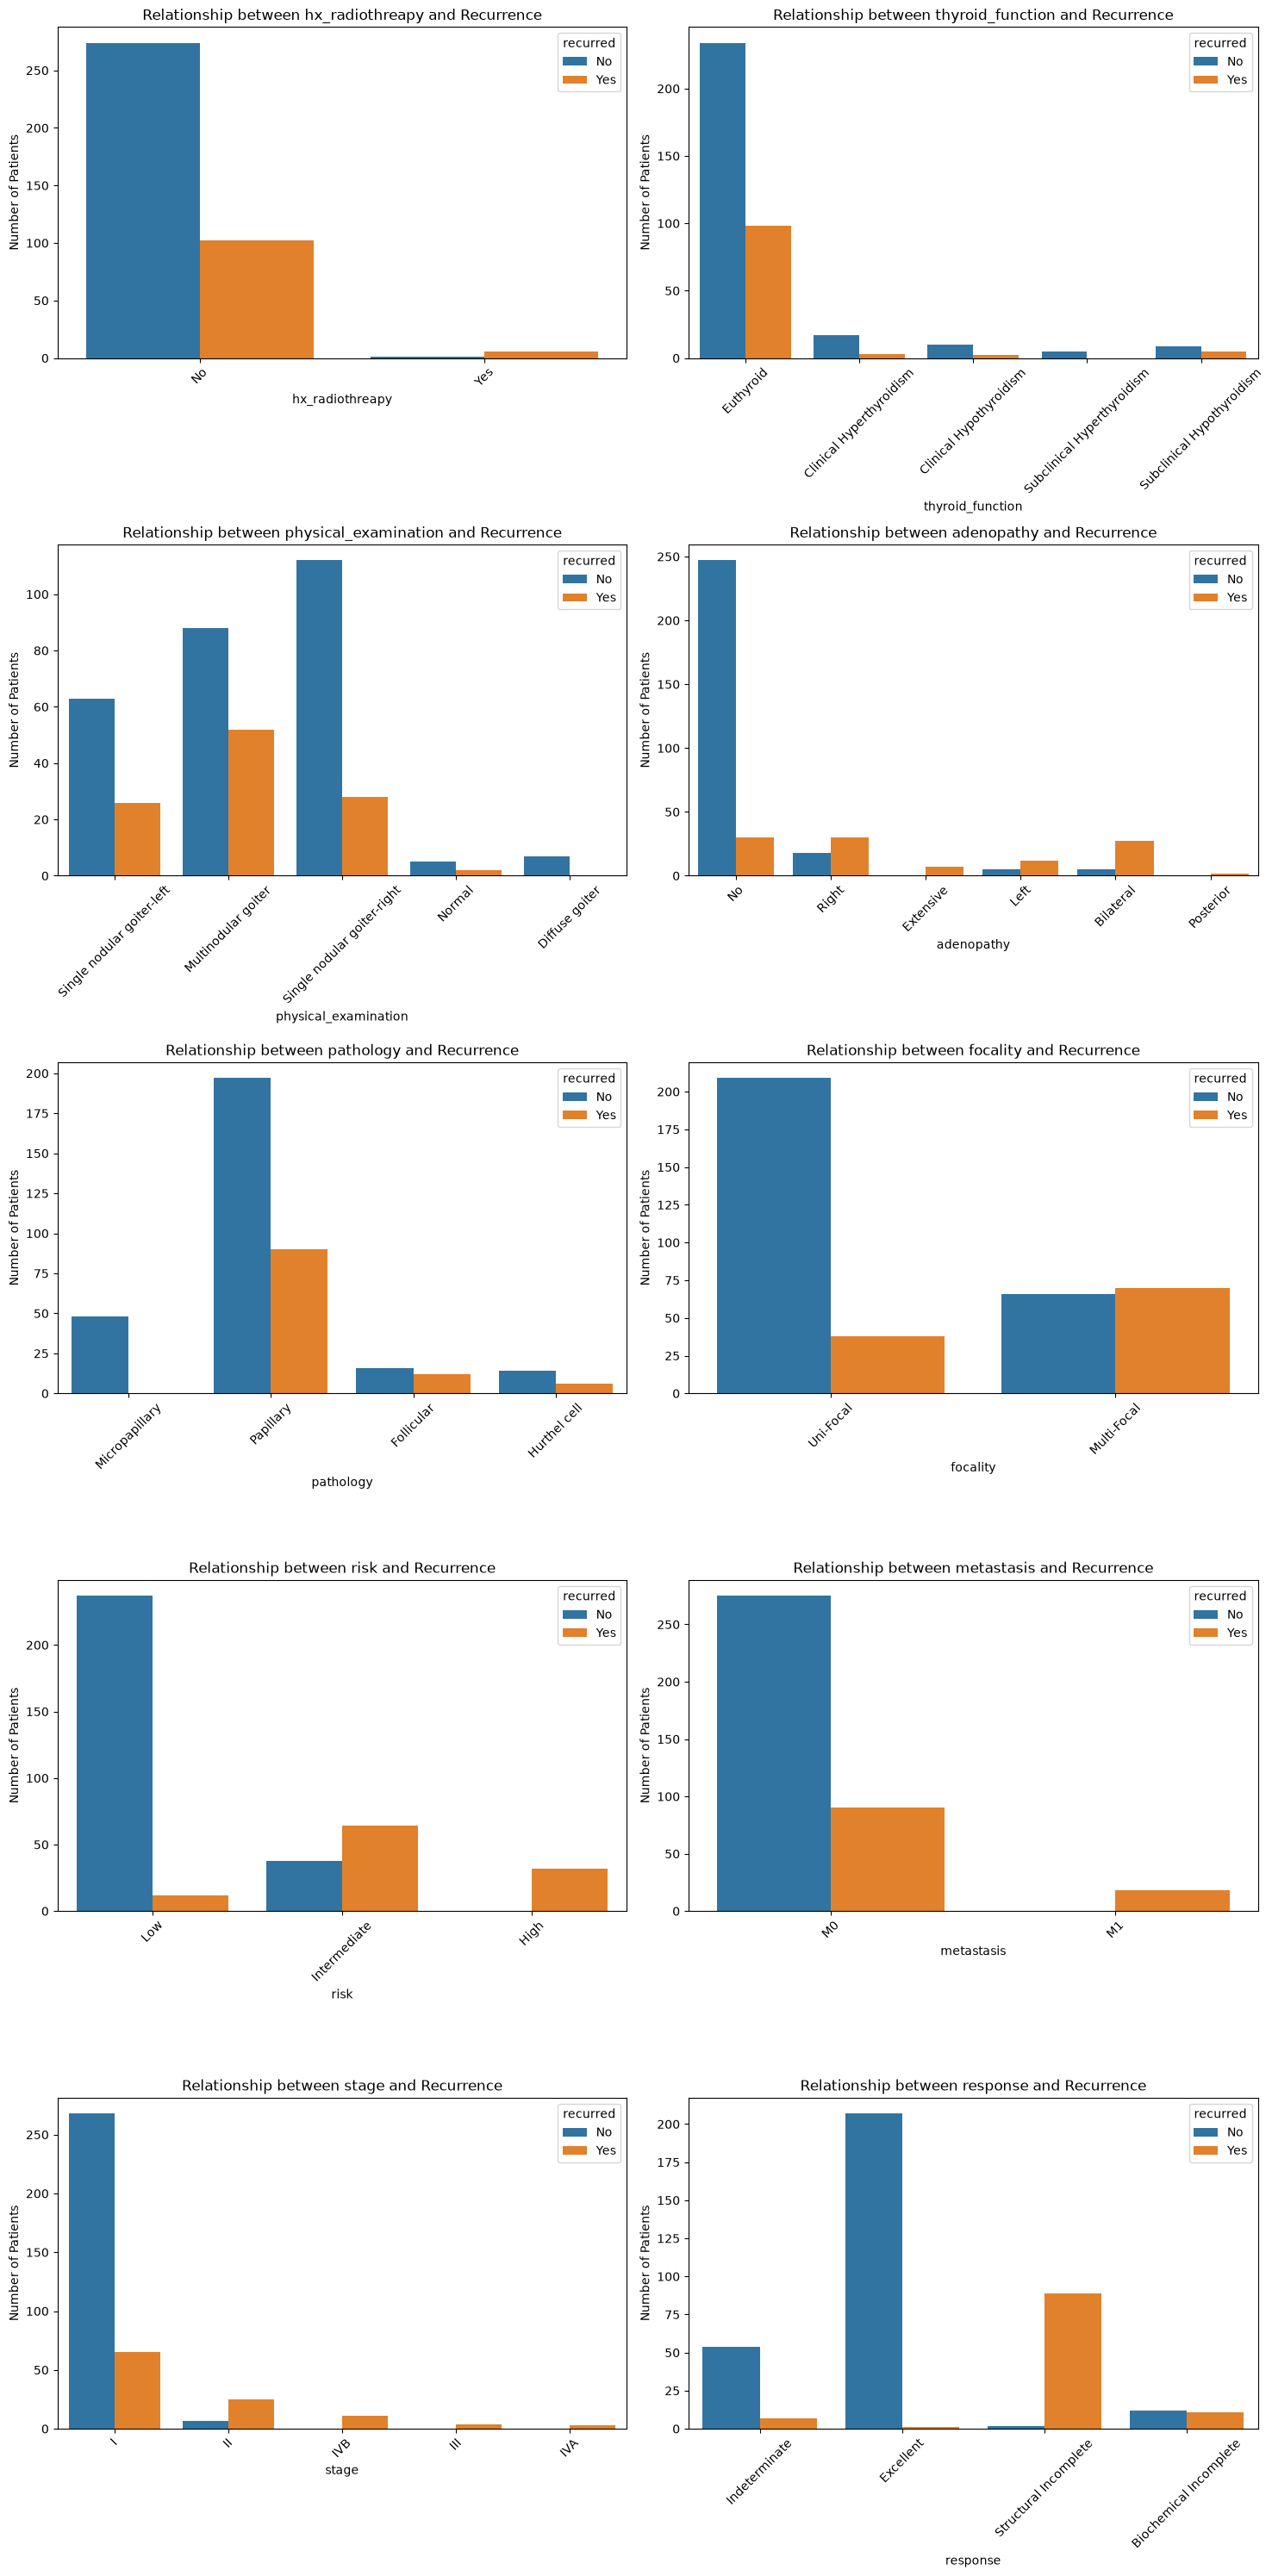

In [147]:
labtest_cols = ['hx_radiothreapy','thyroid_function','physical_examination','adenopathy',
                'pathology','focality','risk','metastasis','stage','response']
fig, axes = plt.subplots(figsize=(15, 30),ncols=2,nrows=5)
axes = axes.flatten()
for index,col in enumerate(labtest_cols):
    sns.countplot(
        data=df,
        x=col,
        hue='recurred',
        ax=axes[index]
    )
    axes[index].set_title(f'Relationship between {col} and Recurrence')
    axes[index].set_xlabel(col)
    axes[index].set_ylabel('Number of Patients')
    axes[index].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

1. Risk classification: Recurrence was uncommon in low-risk patients but considerably more frequent in intermediate- and high-risk groups.
2. Metastasis: All patients with distant metastasis (M1) appeared to experience recurrence.
3. Treatment Response: Patiences with incomplete response showed very high recurrence proportions.
4. Cancer Stage: High cancer stage associated with high recurrence rate.

## 3.Feature Engineering